# BAGEL4 Bacteriocin Analysis

This notebook evaluates PLM-Caliper for FDR-guided annotation of putative bacteriocins using the BAGEL4 benchmark. It searches the putative bacteriocins (queries) and their decoys against the BAGEL4 class I-III bacteriocin database, then calibrates the decoy scores with PLM-Caliper, so that candidate bacteriocin homologs can be selected while with a given target FDR level.

## 0. Setup

Load the libraries, set the paths, the query set, the target database, and the decoy design.

In [1]:
import os
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from Bio import SeqIO

import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.transforms as mtransforms

REPO_ROOT = Path("../..").resolve()
sys.path.insert(0, f"{REPO_ROOT}/src")
sys.path.insert(0, f"{REPO_ROOT}/tutorials/utils")
from PLMCaliper import PLMCaliper, DECOY_DESIGNS # import PLM-Caliper
from fdr import FDREvaluator

In [2]:
QUERY_NAME = "putative" # putative bacteriocins
TARGET_NAME = "class_all" # database, BAGEL4 class I-III bacteriocins
DECOY_DESIGN = "extended_mkv"
MARKOV_ORDER = 2
TARGET_FDR = 0.20
Q_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]  # target FDR levels

DATA_DIR = f"{REPO_ROOT}/data"
OUT_DIR = f"{DATA_DIR}/bagel"
ENV_FILE = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/.env"
RUN_SEARCH = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/run_search.sh"
os.makedirs(OUT_DIR, exist_ok=True)

search2score_mapping = {"plm": "plm", "tmvec": "tmvec", "dhr": "dhr_postprocess"}
METHOD_LABEL = {"plm": "PLMsearch", "tmvec": "TM-Vec", "dhr": "DHR"}

# BAGEL4 bacteriocin classes: 1, 2, 3
CLASSES = ["1", "2", "3"]
CLASS_COLORS = {"1": "#0173B2", "2": "#DE8F05", "3": "#029E73"}
CLASS_MARKERS = {"1": "o", "2": "s", "3": "^"}

decoy_tag = DECOY_DESIGNS[DECOY_DESIGN][1].format(k=MARKOV_ORDER)[1:]
decoy_suffix = DECOY_DESIGNS[DECOY_DESIGN][0].format(k=MARKOV_ORDER)
decoy_tag, decoy_suffix

('extended_mkv2', '_mkv')

## 1. Make decoy

Generate the decoy queries from the putative bacteriocins, `data/putative_extended_mkv2.fa`.

In [3]:
# use PLM-Caliper to make decoys for FDR control
pc = PLMCaliper()
pc.build_decoy(f"{DATA_DIR}/{QUERY_NAME}.fa", design=DECOY_DESIGN, markov_order=MARKOV_ORDER)

[PLMCaliper] built 30 'extended_mkv' decoy sequences (suffix = _mkv)


'/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/putative_extended_mkv2.fa'

## 2. Search database

Search the queries and their decoys against the BAGEL4 database with one retrieval method. Run only the subsection of the method you want to analyze; step 3 calibrates the method searched last.

**Note:** We have saved the search scores used in the paper on [Hugging Face](https://huggingface.co/datasets/yifanyang993/PLMCaliper-extras/tree/main/raw/scores/search_data). When they are already in `data/`, the searches below are skipped.

Put the downloaded files here (DHR as an example):

```text
data/
├── result_dhr_putative_class_all.txt                 # real query scores
└── result_dhr_putative_extended_mkv2_class_all.txt   # decoy scores
```

### 2-1. DHR

Convert the FASTA files to the .tsv format DHR reads, run DHR, then flip its distances into similarity scores.

In [6]:
searching_method = "dhr"
score_method = search2score_mapping[searching_method]
from fa2tsv import fa2tsv
from process_searching_score import dhr_postprocess

# use /PLM_searching_cmds/run_search.sh for dhr; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.tsv"
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    processed = f"{DATA_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(processed) and os.path.getsize(processed) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    # dhr reads .tsv files instead of FASTA
    for fa_name in (name, TARGET_NAME):
        fa2tsv(f"{DATA_DIR}/{fa_name}.fa", f"{DATA_DIR}/{fa_name}.tsv")
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{DATA_DIR}/{name}.tsv" -t "{target}"'], check=True)

    # flip this query's dhr distances into similarity scores
    dhr_postprocess(DATA_DIR, name, TARGET_NAME, [])

[OK] 30 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/putative.tsv
[OK] 791 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/class_all.tsv
[run_search] dhr | query=putative target=class_all (791 seqs) | k=791


/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/libs/Dense-Homolog-Retrieval-main/do_embedding.py:41: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  @hydra.main(config_path="conf", config_name="pred_conf")
/home/yfnyang/miniforge3/envs/dhr/lib/python3.11/site-packages/hydra/_internal/hydra.py:119: UserWarning: Future Hydra versions will no longer change working directory at job runtime by default.
See https://hydra.cc/docs/1.2/upgrades/1.1_to_1.2/changes_to_job_working_dir/ for more information.
  ret = run_job(
Seed set to 1234
/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/libs/Dense-Homolog-Retrieval-main/mydpr/model/biencoder.py:50: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See h

/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/libs/Dense-Homolog-Retrieval-main/dhr2_ckpt


/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/libs/Dense-Homolog-Retrieval-main/mydpr/model/biencoder.py:51: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  bert2, _ = torch.lo

Predicting DataLoader 0: 100%|██████████| 16/16 [00:01<00:00,  8.04it/s]


...

[OK] Saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_putative_class_all.txt
[run_search] dhr done -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_putative_class_all.txt
                                   qid                     tid       score  \
0  111.1;SCAB_84151_putative_Linaridin  456.1;Phakellistatin_8  103.395805   
1  111.1;SCAB_84151_putative_Linaridin      410.1;Hymenamide_H  102.058960   
2  111.1;SCAB_84151_putative_Linaridin  457.1;Phakellistatin_9  101.826057   
3  111.1;SCAB_84151_putative_Linaridin     69.2;Divergicin_M35  101.401260   
4  111.1;SCAB_84151_putative_Linaridin  454.1;Phakellistatin_2  100.782860   

   homo_type  rank  
0          1     1  
1          1     2  
2          1     3  
3         -1     4  
4          1     5  
Saved to: /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_postprocess_putative_class_all.txt
[OK] 30 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/putative_extended_mkv

/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/libs/Dense-Homolog-Retrieval-main/mydpr/model/biencoder.py:50: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  bert1, alphabet = t

Load ckp cost: 1.489499 s


Processing homo type: 100%|██████████| 23730/23730 [00:00<00:00, 29908.62it/s]


[OK] Saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_putative_extended_mkv2_class_all.txt
[run_search] dhr done -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_putative_extended_mkv2_class_all.txt
                                       qid                     tid  \
0  111.1;SCAB_84151_putative_Linaridin_mkv      410.1;Hymenamide_H   
1  111.1;SCAB_84151_putative_Linaridin_mkv  456.1;Phakellistatin_8   
2  111.1;SCAB_84151_putative_Linaridin_mkv    471.1;Stylissamide_B   
3  111.1;SCAB_84151_putative_Linaridin_mkv        469.1;Stylisin_2   
4  111.1;SCAB_84151_putative_Linaridin_mkv  457.1;Phakellistatin_9   

        score  homo_type  rank  
0  100.469673          1     1  
1   98.693596          1     2  
2   98.537502          1     3  
3   98.327293          1     4  
4   97.931061          1     5  
Saved to: /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/result_dhr_postprocess_putative_extended_mkv2_class_all.txt


### 2-2. PLMsearch

Run PLMsearch on the queries and the decoys.

In [4]:
searching_method = "plm"  # PLMsearch
score_method = search2score_mapping[searching_method]

# use /PLM_searching_cmds/run_search.sh for plmsearch; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.fa"
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    result = f"{DATA_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{DATA_DIR}/{name}.fa" -t "{target}"'], check=True)

[skip] For time-saving, plm-putative scores already exist
[skip] For time-saving, plm-putative_extended_mkv2 scores already exist


### 2-3. TM-Vec

Run TM-Vec on the queries and the decoys.

In [5]:
searching_method = "tmvec"
score_method = search2score_mapping[searching_method]

# use /PLM_searching_cmds/run_search.sh for tmvec; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.fa"
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    result = f"{DATA_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{DATA_DIR}/{name}.fa" -t "{target}"'], check=True)

[skip] For time-saving, tmvec-putative scores already exist
[skip] For time-saving, tmvec-putative_extended_mkv2 scores already exist


## 3. Run PLM-Caliper

Calibrate the decoy scores with PLM-Caliper, and attach the homology labels to the noise-matched target table. To calibrate another method, set `searching_method` to `plm`, `tmvec` or `dhr` before running this cell.

The two tables the later BAGEL steps read go to `data/bagel/` (TM-Vec as an example):

```text
data/bagel/
├── result_tmvec_putative_target_noisy_class_all.txt # noisy target scores
└── result_tmvec_putative_extended_mkv2_calibrated_gam_AdaptiveBell_class_all.txt # calibrated decoy scores
```

In [7]:
searching_method = "dhr"
score_method = search2score_mapping[searching_method]
raw_real = f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{TARGET_NAME}.txt"
raw_decoy = f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tag}_{TARGET_NAME}.txt"
out_real = f"{OUT_DIR}/result_{score_method}_{QUERY_NAME}_target_noisy_{TARGET_NAME}.txt"
out_decoy = f"{OUT_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tag}_calibrated_gam_AdaptiveBell_{TARGET_NAME}.txt"

# loading data
df_real = pd.read_csv(raw_real, sep="\t").dropna(subset=["score"])
df_decoy = pd.read_csv(raw_decoy, sep="\t").dropna(subset=["score"])

# run PLM-Caliper
pc = PLMCaliper(decoy_suffix=decoy_suffix, tau=0.25)
calibrated_decoy, noisy_target, efdps, cutoffs, hits = pc.plmcaliper(df_real, df_decoy, [TARGET_FDR])

# attach the homology labels to the noise-matched target table, then save the two tables the later steps read
noisy_target = noisy_target.merge(df_real[["qid", "tid", "homo_type"]], on=["qid", "tid"], how="left")
noisy_target.to_csv(out_real, sep="\t", index=False)
calibrated_decoy.to_csv(out_decoy, sep="\t", index=False)
print(f"[OK] {out_real}\n[OK] {out_decoy}")

[PLMCaliper] fitting weights function
[PLMCaliper] doing per-query calibration (tau=0.25)


[OK] /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/bagel/result_dhr_postprocess_putative_target_noisy_class_all.txt
[OK] /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/bagel/result_dhr_postprocess_putative_extended_mkv2_calibrated_gam_AdaptiveBell_class_all.txt


## 4. Discovery

For each putative query, accept the BAGEL4 targets whose eFD from PLM-Caliper stays within a target FDR. Each hit gets a q-value, the lowest eFDP of any score threshold that still accepts it, so the hits accepted at target FDR q are exactly those with q-value <= q. 

In [10]:
def discovery(searching_method):
    score_method = search2score_mapping[searching_method]
    ev = FDREvaluator(decoy_suffix)
    pairs = ev.pair_table(pd.read_csv(f"{OUT_DIR}/result_{score_method}_{QUERY_NAME}_target_noisy_{TARGET_NAME}.txt", sep="\t"),
                          pd.read_csv(f"{OUT_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tag}_calibrated_gam_AdaptiveBell_{TARGET_NAME}.txt", sep="\t"))
    hits = []
    for qid, df_q in pairs.groupby("qid", sort=False):
        curve = ev.efdp_curve(df_q["score_real"].to_numpy(float), df_q["score_decoy"].to_numpy(float))
        at = np.searchsorted(curve["cand"], df_q["score_real"].to_numpy(float), side="right") - 1
        hits.append(df_q.assign(q_hit=np.minimum.accumulate(curve["efdp"])[at]))
    hits = pd.concat(hits)
    return hits.loc[hits["q_hit"] <= max(Q_LEVELS), ["qid", "tid", "score_real", "q_hit"]]

# discovery
hits = {m: discovery(m) for m in search2score_mapping}
counts = {}
for m, h in hits.items():
    n_queries = []
    for q in Q_LEVELS:
        accepted = h[h["q_hit"] <= q] 
        n_queries.append(accepted["qid"].nunique())
    counts[METHOD_LABEL[m]] = n_queries
summary = pd.DataFrame(counts, index=pd.Index(Q_LEVELS, name="target FDR"))

## 5. t-SNE coordinates

Place every putative and BAGEL4 sequence on the published t-SNE map of their TM-Vec embeddings. The first plot shows where the putative queries fall among the three BAGEL4 classes; the second shows one query's accepted hits, coloured by the lowest target FDR at which each hit is accepted.

Download the t-SNE map from [Hugging Face](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/tsne) and put the three files here:

```text
data/bagel/
├── X_2d_all.npy     # t-SNE coordinates of every sequence
├── seqs_all.npy     # the sequence ids, in the same order
└── labels_all.npy   # BAGEL class of each sequence
```

In [12]:
def load_tsne():
    ids = np.load(f"{OUT_DIR}/seqs_all.npy", allow_pickle=True).astype(str)
    xy = np.load(f"{OUT_DIR}/X_2d_all.npy")
    return pd.DataFrame({"x": xy[:, 0], "y": xy[:, 1],
                         "cls": [i.split(";")[0].split(".")[1] for i in ids],
                         "putative": np.load(f"{OUT_DIR}/labels_all.npy", allow_pickle=True) == "Putative"}, index=ids)

tsne = load_tsne()

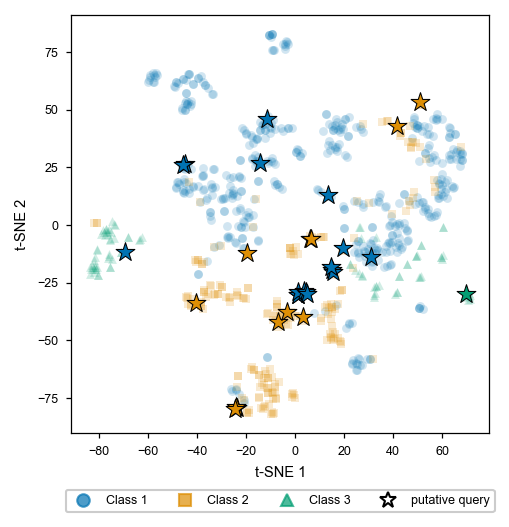

In [13]:
# overall tsne plot
plt.rcParams.update({"pdf.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Helvetica", "Arial", "Nimbus Sans", "Liberation Sans", "TeX Gyre Heros", "DejaVu Sans"],
                     "font.size": 6, "axes.labelsize": 7, "axes.titlesize": 7, "legend.fontsize": 6, "legend.framealpha": 1.0,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5, "figure.dpi": 150})

def plot_tsne_overview(tsne):
    fig, ax = plt.subplots(figsize=(3.6, 4.0))
    for c in CLASSES:
        bg, query = tsne[~tsne["putative"] & (tsne["cls"] == c)], tsne[tsne["putative"] & (tsne["cls"] == c)]
        ax.scatter(bg["x"], bg["y"], s=18, c=CLASS_COLORS[c], marker=CLASS_MARKERS[c], alpha=0.18, linewidths=0)
        ax.scatter(query["x"], query["y"], s=90, c=CLASS_COLORS[c], marker="*", edgecolors="black", linewidths=0.5, zorder=3)
    handles = [mlines.Line2D([], [], ls="", marker=CLASS_MARKERS[c], color=CLASS_COLORS[c], alpha=0.7, label=f"Class {c}")
               for c in CLASSES] + [mlines.Line2D([], [], ls="", marker="*", mfc="white", mec="black", ms=8, label="putative query")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
    ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.set_box_aspect(1)
    plt.show()

plot_tsne_overview(tsne)

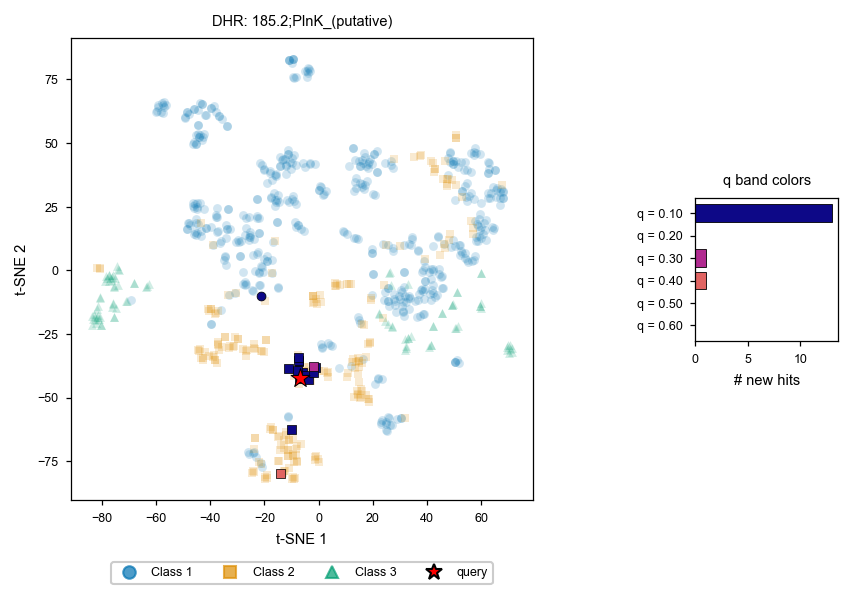

In [14]:
# per-query tsne plot
def plot_tsne_query(tsne, hits, searching_method, qid):
    df = hits[searching_method]
    h = df[df["qid"] == qid]
    first_q = {t: min(q for q in Q_LEVELS if q_hit <= q) for t, q_hit in zip(h["tid"], h["q_hit"])}
    q_colors = dict(zip(Q_LEVELS, plt.cm.plasma(np.linspace(0, 1, len(Q_LEVELS)))))
    fig, (ax, ax_bar) = plt.subplots(1, 2, figsize=(7.2, 4.0), gridspec_kw={"width_ratios": [4.2, 1.0], "wspace": 0.25})
    bg, hit = tsne.drop(index=[qid, *first_q]), tsne.loc[list(first_q)]
    for c in CLASSES:
        b, hc = bg[bg["cls"] == c], hit[hit["cls"] == c]
        ax.scatter(b["x"], b["y"], s=18, c=CLASS_COLORS[c], marker=CLASS_MARKERS[c], alpha=0.18, linewidths=0)
        ax.scatter(hc["x"], hc["y"], s=18, c=[q_colors[first_q[t]] for t in hc.index], marker=CLASS_MARKERS[c],
                   edgecolors="black", linewidths=0.35, zorder=3)
    ax.scatter(tsne.loc[qid, "x"], tsne.loc[qid, "y"], s=90, c="red", marker="*", edgecolors="black", linewidths=0.5, zorder=4)
    handles = [mlines.Line2D([], [], ls="", marker=CLASS_MARKERS[c], color=CLASS_COLORS[c], alpha=0.7, label=f"Class {c}")
               for c in CLASSES] + [mlines.Line2D([], [], ls="", marker="*", mfc="red", mec="black", ms=8, label="query")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
    ax.set(title=f"{METHOD_LABEL[searching_method]}: {qid}", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.set_box_aspect(1)
    ax_bar.barh([f"q = {q:.2f}" for q in Q_LEVELS], [list(first_q.values()).count(q) for q in Q_LEVELS],
                color=[q_colors[q] for q in Q_LEVELS], edgecolor="black", linewidth=0.4)
    ax_bar.invert_yaxis()
    ax_bar.set(title="q band colors", xlabel="# new hits")
    ax_bar.set_box_aspect(1)
    plt.show()

# example
QUERY = "185.2;PlnK_(putative)"
plot_tsne_query(tsne, hits, searching_method, QUERY)

## 6. Class assignment of the putative queries

Assign each putative query a BAGEL class from its accepted hits (q-value ≤ 0.6). For each class, the weighted q-value averages the q-values of the query's hits in that class, padding a class that has fewer hits with the cutoff; the class with the lowest weighted q-value is assigned, and tied classes are all kept. The three plots below show the class composition of each query's hits, the weighted q-value per class, and the queries on the t-SNE map filled with their assigned class. They use DHR, the method currently set in `searching_method`.

In [15]:
CUTOFF = 0.6  # q-value cutoff for the accepted hits used to assign a class

def class_assignment(tsne, hits, searching_method):
    df = hits[searching_method]
    h = df[df["q_hit"] <= CUTOFF]
    h = h.assign(cls=h["tid"].str.split(";").str[0].str.split(".").str[1])

    # putative queries ordered by their BAGEL class, then by id number
    queries = sorted(tsne.index[tsne["putative"]], key=lambda q: (tsne.loc[q, "cls"], int(q.split(".")[0])))
    table = lambda v, f: h.pivot_table(index="qid", columns="cls", values=v, aggfunc=f).reindex(index=queries, columns=CLASSES).fillna(0)
    counts, sum_q = table("tid", "count"), table("q_hit", "sum")
    n_pad = counts.max(axis=1)
    wq = (sum_q + CUTOFF * counts.rsub(n_pad, axis=0)).div(n_pad, axis=0).where(counts > 0)
    winners = {q: [c for c in CLASSES if np.isclose(wq.loc[q, c], wq.loc[q].min(), rtol=1e-9, atol=1e-12)] for q in queries}
    return counts, wq, winners

counts, wq, winners = class_assignment(tsne, hits, searching_method)
wq.round(3).assign(assigned_class=["|".join(w) for w in winners.values()], bagel_class=tsne.loc[wq.index, "cls"])

cls,1,2,3,assigned_class,bagel_class
qid,,,,,
33.1;FrEUN1f_DRAFT_0188_putative_Linaridin,0.600,0.600,NaN,1|2,1
44.1;Htur_3018_putative_Linaridin,0.554,0.596,NaN,1,1
56.1;Lxx19440_putative_Linaridin,0.500,NaN,NaN,1,1
57.1;Lxx19470_putative_Linaridin,0.333,NaN,NaN,1,1
75.1;Mvan_2782_putative_Linaridin,0.538,0.592,NaN,1,1
82.1;Nmul_A1818_putative_Linaridin,0.500,0.500,NaN,1|2,1
94.1;putative_lantibiotic,0.430,0.593,NaN,1,1
95.1;putative_lantibiotic,0.564,0.597,NaN,1,1
96.1;putative_lantibiotic,0.167,0.567,NaN,1,1


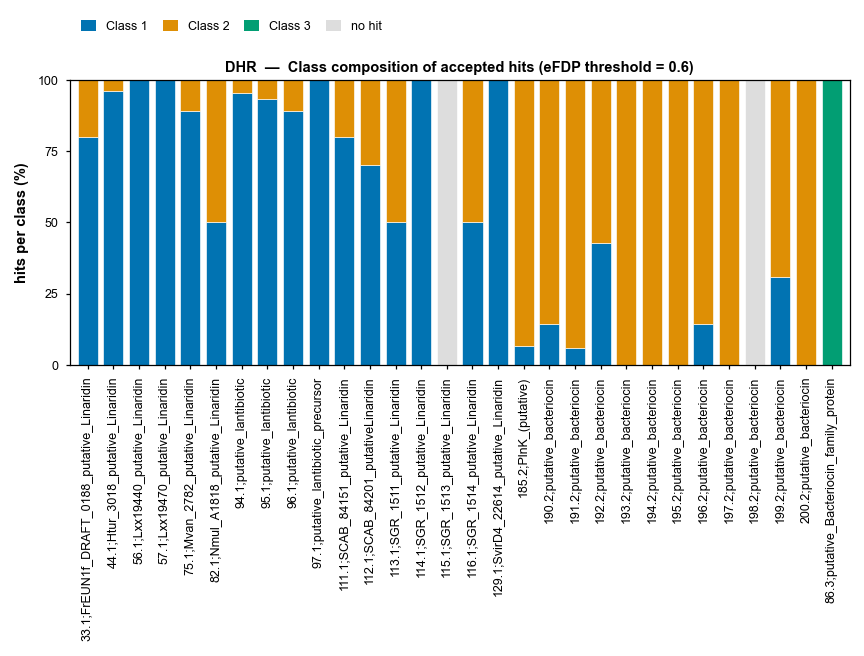

In [16]:
# class composition plot
def plot_class_composition(counts, searching_method):
    queries, ax_w, ax_h = list(counts.index), 5.2, 1.9
    left, right, top = 0.55, 0.10, 0.45
    bottom = max(1.5, max(map(len, queries)) * 0.62 * 6 / 72 + 0.12)
    fig_w, fig_h = ax_w + left + right, ax_h + top + bottom
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([left / fig_w, bottom / fig_h, ax_w / fig_w, ax_h / fig_h])
    pct = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
    x, stack = np.arange(len(queries)), np.zeros(len(queries))
    for c in CLASSES:
        ax.bar(x, pct[c], bottom=stack, width=0.78, color=CLASS_COLORS[c], edgecolor="white", linewidth=0.3, zorder=2)
        stack += pct[c].to_numpy()
    no_hit = counts.sum(axis=1).to_numpy() == 0
    ax.bar(x[no_hit], 100, width=0.78, color="#DDDDDD", edgecolor="white", linewidth=0.3, zorder=2)
    ax.set(xlim=(-0.7, len(queries) - 0.3), ylim=(0, 100), yticks=[0, 25, 50, 75, 100], xticks=x)
    ax.set_xticklabels(queries, rotation=90)
    ax.set_ylabel("hits per class (%)", fontweight="bold")
    ax.tick_params(length=2.0)
    ax.set_title(f"{METHOD_LABEL[searching_method]}  —  Class composition of accepted hits (eFDP threshold = {CUTOFF:g})",
                 fontweight="bold", pad=4)
    handles = [mpatches.Patch(facecolor=CLASS_COLORS[c], label=f"Class {c}") for c in CLASSES]
    handles += [mpatches.Patch(facecolor="#DDDDDD", label="no hit")] if no_hit.any() else []
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.0 + 0.24 / ax_h), ncol=len(handles),
              frameon=False, handlelength=1.2, handleheight=1.0, columnspacing=1.2)
    plt.show()

plot_class_composition(counts, searching_method)

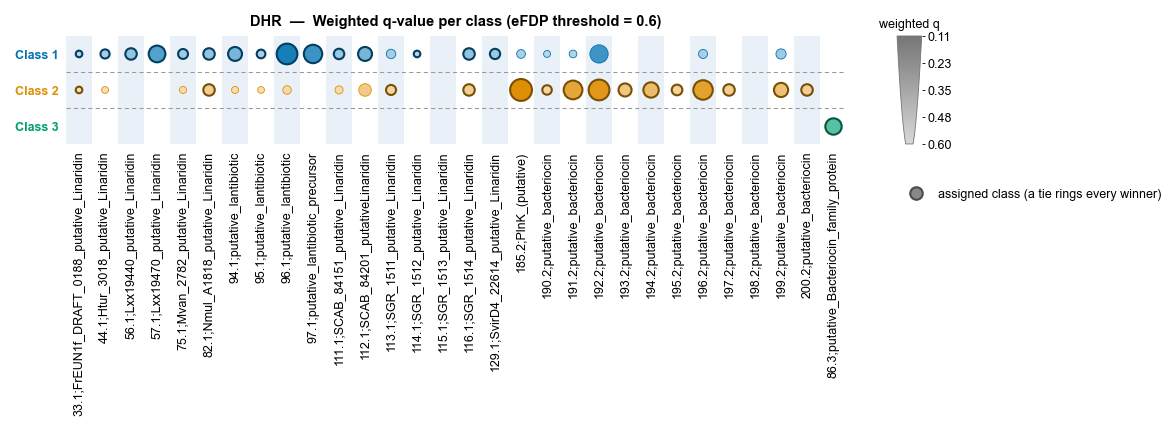

In [18]:
# weighted q-value per class plot
def plot_weighted_q(wq, winners, searching_method):
    queries, n = list(wq.index), len(wq)
    q_lo = np.nanmin(wq.to_numpy(float))  # the best weighted q gets the largest, darkest dot
    frac = lambda q: np.clip((CUTOFF - np.asarray(q, float)) / max(CUTOFF - q_lo, 1e-9), 0, 1)
    area = lambda q: 10 + 100 * frac(q)
    tint = lambda color, f: tuple(1 - (0.28 + 0.72 * f) * (1 - v) for v in mcolors.to_rgb(color))
    darker = lambda color: tuple(0.55 * v for v in mcolors.to_rgb(color))
    ax_w, ax_h, left, right, top = 5.2 / 30 * n, 0.24 * len(CLASSES), 0.62, 1.45, 0.30
    bottom = max(1.45, max(map(len, queries)) * 0.62 * 6 / 72 + 0.12)
    fig_w, fig_h = ax_w + left + right, ax_h + top + bottom
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([left / fig_w, bottom / fig_h, ax_w / fig_w, ax_h / fig_h])
    for j in range(0, n, 2):
        ax.axvspan(j - 0.5, j + 0.5, facecolor="#EAF0F7", edgecolor="none", zorder=0)
    for i in range(1, len(CLASSES)):
        ax.axhline(i - 0.5, color="#999999", linewidth=0.5, linestyle=(0, (4, 3)), zorder=2)
    x = np.arange(n)
    for i, c in enumerate(CLASSES):
        q = wq[c].to_numpy(float)
        ok = ~np.isnan(q)
        won = ok & np.array([c in winners[qid] for qid in queries])
        for mask, edge, lw, z in ((ok & ~won, CLASS_COLORS[c], 0.4, 3), (won, darker(CLASS_COLORS[c]), 1.0, 4)):
            if mask.any():
                ax.scatter(x[mask], np.full(mask.sum(), i), s=area(q[mask]), c=[tint(CLASS_COLORS[c], f) for f in frac(q[mask])],
                           edgecolors=[edge], linewidths=lw, zorder=z)
    ax.set(xlim=(-0.5, n - 0.5), ylim=(len(CLASSES) - 0.5, -0.5), xticks=x, yticks=range(len(CLASSES)))
    ax.set_xticklabels(queries, rotation=90)
    ax.set_yticklabels([f"Class {c}" for c in CLASSES], fontweight="bold")
    for tick, c in zip(ax.get_yticklabels(), CLASSES):
        tick.set_color(CLASS_COLORS[c])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{METHOD_LABEL[searching_method]}  —  Weighted q-value per class (eFDP threshold = {CUTOFF:g})",
                 fontweight="bold", pad=5)
    ax.legend(handles=[mlines.Line2D([], [], marker="o", ls="", mfc="#888888", mec=darker("#888888"), mew=1.0, ms=6,
                                     label="assigned class" + (" (a tie rings every winner)" if any(len(w) > 1 for w in winners.values()) else ""))],
              loc="upper left", frameon=False, handletextpad=0.8, borderpad=0.0, bbox_to_anchor=(1.0 + 0.34 / ax_w, -0.35))
    key = fig.add_axes([(left + ax_w + 0.34) / fig_w, bottom / fig_h, 2 * np.sqrt(110 / np.pi) / 72 / fig_w, ax_h / fig_h])
    qs = np.linspace(q_lo, CUTOFF, 512)
    radius = np.sqrt(area(qs) / np.pi)
    img = key.imshow(np.array([tint("#767676", f) for f in frac(qs)]).reshape(-1, 1, 3), extent=(-radius[0], radius[0], CUTOFF, q_lo),
                     origin="upper", aspect="auto", interpolation="bilinear", zorder=1)
    wedge = np.concatenate([np.column_stack([radius, qs]), np.column_stack([-radius[::-1], qs[::-1]])])
    img.set_clip_path(mpatches.Polygon(wedge, closed=True, transform=key.transData))
    key.add_patch(mpatches.Polygon(wedge, closed=True, facecolor="none", edgecolor="#767676", linewidth=0.4, clip_on=False, zorder=2))
    key.set(xlim=(-radius[0], radius[0]), ylim=(CUTOFF, q_lo), xticks=[], yticks=np.linspace(q_lo, CUTOFF, 5))
    key.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    key.yaxis.tick_right()
    key.tick_params(axis="y", length=1.5, width=0.4, pad=1.5)
    for spine in key.spines.values():
        spine.set_visible(False)
    key.set_title("weighted q", fontsize=6, pad=4)
    plt.show()

plot_weighted_q(wq, winners, searching_method)

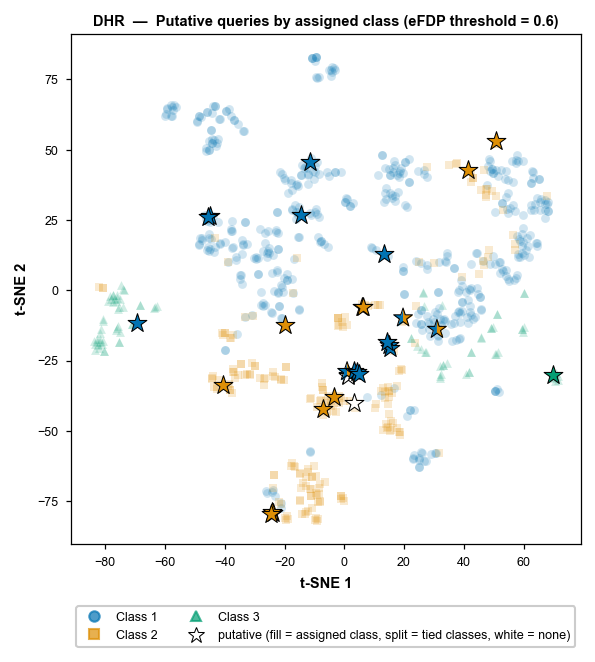

In [ ]:
# putative queries by assigned class plot
def plot_assigned_class_map(tsne, winners, searching_method):
    ax_size, left, right, top, bottom = 3.4, 0.58, 0.08, 0.30, 0.95
    fig_w, fig_h = ax_size + left + right, ax_size + top + bottom
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([left / fig_w, bottom / fig_h, ax_size / fig_w, ax_size / fig_h])
    for c in CLASSES:
        bg = tsne[~tsne["putative"] & (tsne["cls"] == c)]
        ax.scatter(bg["x"], bg["y"], s=18, c=CLASS_COLORS[c], marker=CLASS_MARKERS[c], alpha=0.18, linewidths=0, zorder=1)
    for k, qid in enumerate(sorted(winners)):
        x, y = tsne.loc[qid, ["x", "y"]]
        colors = [CLASS_COLORS[c] for c in winners[qid]] or ["#FFFFFF"]
        if len(colors) > 1:  # tie
            trans = mtransforms.Affine2D().scale(1 / 72) + fig.dpi_scale_trans + mtransforms.ScaledTranslation(x, y, ax.transData)
            for i, color in enumerate(colors):
                a = np.radians(np.linspace(90 + i * 360 / len(colors), 90 + (i + 1) * 360 / len(colors), 33))
                sector = mpatches.Polygon(np.vstack([[0, 0], np.column_stack([2 * np.sqrt(90) * np.cos(a), 2 * np.sqrt(90) * np.sin(a)])]),
                                          closed=True, transform=trans)
                ax.scatter([x], [y], marker="*", s=90, c=[color], linewidths=0, zorder=100 + 2 * k).set_clip_path(sector)
            colors = ["none"]
        ax.scatter([x], [y], marker="*", s=90, facecolors=colors[0], edgecolors="black", linewidths=0.5, zorder=101 + 2 * k)
    ax.set_xlabel("t-SNE 1", fontweight="bold")
    ax.set_ylabel("t-SNE 2", fontweight="bold")
    ax.set_title(f"{METHOD_LABEL[searching_method]}  —  Putative queries by assigned class (eFDP threshold = {CUTOFF:g})",
                 fontweight="bold", pad=4)
    notes = ["fill = assigned class"] + ["split = tied classes"] * any(len(w) > 1 for w in winners.values()) \
            + ["white = none"] * any(not w for w in winners.values())
    handles = [mlines.Line2D([], [], marker=CLASS_MARKERS[c], ls="", mfc=CLASS_COLORS[c], mec=CLASS_COLORS[c], ms=5, alpha=0.7,
                             label=f"Class {c}") for c in CLASSES]
    handles += [mlines.Line2D([], [], marker="*", ls="", mfc="#FFFFFF", mec="black", mew=0.5, ms=8, label=f"putative ({', '.join(notes)})")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=True)
    plt.show()

plot_assigned_class_map(tsne, winners, searching_method)

## 7. Alignment heatmaps

Residue-alignment probabilities from DeepBLAST between the example query and its best accepted hit. DeepBLAST embeds both sequences with ProtT5 and returns the probability that each query residue aligns with each target residue.

/home/yfnyang/miniforge3/envs/plmcaliper/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/yfnyang/miniforge3/envs/plmcaliper/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


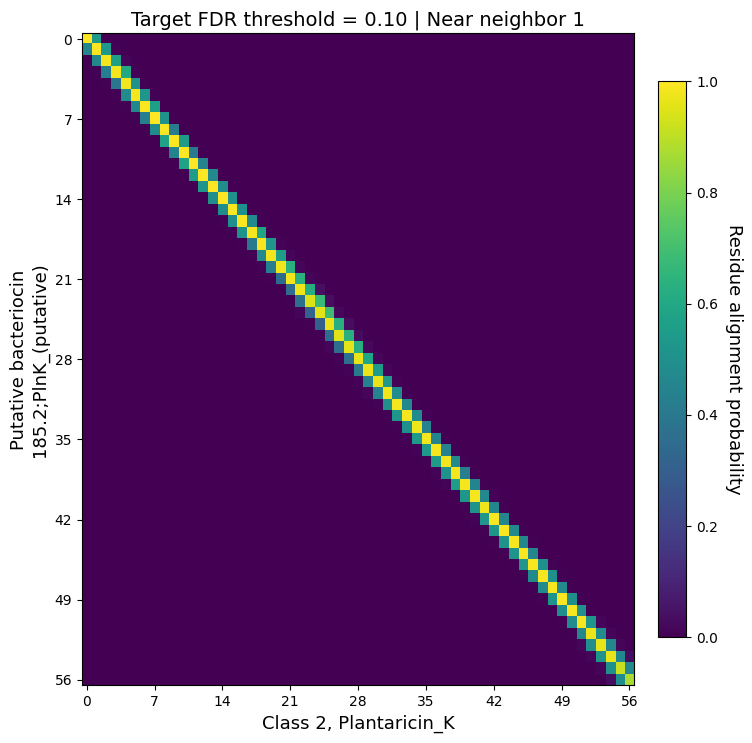

In [20]:
import torch
from deepblast.dataset.utils import get_sequence, pack_sequences
from deepblast.trainer import DeepBLAST
from transformers import T5EncoderModel, T5Tokenizer


def plot_alignment_heatmap(hits, searching_method, qid, tid):
    # DeepBLAST, with the ProtT5 encoder it embeds the sequences with
    prott5 = "Rostlab/prot_t5_xl_half_uniref50-enc"
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model = DeepBLAST(layers=8, alignment_mode="needleman-wunsch", dropout=0.5, device="gpu" if device.type == "cuda" else "cpu")
    model.load_state_dict(torch.load(f"{REPO_ROOT}/libs/tm-vec-master/model/deepblast-v3.ckpt", map_location="cpu"))
    model.tokenizer = T5Tokenizer.from_pretrained(prott5, do_lower_case=False, legacy=True, local_files_only=True)
    model.aligner.lm = T5EncoderModel.from_pretrained(prott5, local_files_only=True)
    model = model.to(device).eval()

    # residue-alignment probability of every query/target residue pair
    seqs = {r.id: str(r.seq).upper() for name in (QUERY_NAME, TARGET_NAME) for r in SeqIO.parse(f"{DATA_DIR}/{name}.fa", "fasta")}
    query, target = seqs[qid], seqs[tid]
    seq, order = pack_sequences(*([get_sequence(s, model.tokenizer)[0].to(device)] for s in (query, target)))
    with torch.enable_grad():
        aln = model(seq.to(device), order)[0].squeeze(0).detach().cpu().numpy()[:len(query), :len(target)].astype(np.float32)
    heat = np.clip(np.nan_to_num(aln, nan=0.0, posinf=1.0, neginf=0.0), 0.0, 1.0)

    q_hit = hits[searching_method].query("qid == @qid and tid == @tid")["q_hit"].iloc[0]
    ticks = lambda n: sorted({int(round(x)) for x in np.linspace(0, n - 1, min(9, n))})
    with plt.style.context("default"):  # the heatmaps in the paper use matplotlib's default style
        fig, ax = plt.subplots(figsize=(max(4.8, min(8.2, 2.5 + 0.09 * heat.shape[1])), max(4.6, min(8.2, 2.4 + 0.09 * heat.shape[0]))))
        im = ax.imshow(heat, origin="upper", aspect="auto", interpolation="nearest", cmap="viridis", vmin=0.0, vmax=1.0)
        ax.set(xticks=ticks(heat.shape[1]), yticks=ticks(heat.shape[0]))
        ax.set_title(f"Target FDR threshold = {min(q for q in Q_LEVELS if q_hit <= q):.2f} | Near neighbor 1", fontsize=14)
        ax.set_ylabel(f"Putative bacteriocin\n{qid}", fontsize=13)
        ax.set_xlabel(f"Class {tid.split(';')[0].split('.')[1]}, {tid.split(';', 1)[1]}", fontsize=13)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Residue alignment probability", rotation=270, labelpad=18, fontsize=13)
        fig.tight_layout()
        plt.show()

# example: 185.2 PlnK and its best match, plantaricin K
plot_alignment_heatmap(hits, searching_method, QUERY, "173.2;Plantaricin_K")